# Assignment 2, Part 3: Linear Regression

Linear regression trained with batch gradient descent. The learning rate is chosen by 10-fold cross validation over 0 to 0.1 in steps of 0.01, then the best rate is scored on the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

## Load the data
The `regression-dataset` folder must sit next to this notebook.

In [2]:
X_train = pd.read_csv('regression-dataset/train_inputs.csv', header=None).values
y_train = pd.read_csv('regression-dataset/train_targets.csv', header=None).values.ravel()
X_test = pd.read_csv('regression-dataset/test_inputs.csv', header=None).values
y_test = pd.read_csv('regression-dataset/test_targets.csv', header=None).values.ravel()

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (200, 2)  Test: (100, 2)


In [ ]:
EPOCHS = 1000

def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

def train(X, y, lr, epochs=EPOCHS):
    Xb = add_bias(X)
    w = np.zeros(Xb.shape[1])
    for _ in range(epochs):
        grad = (2 / len(y)) * Xb.T @ (Xb @ w - y)
        # update weights
        w = w - lr * grad
    return w

def predict(X, w):
    return add_bias(X) @ w

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

## 10-fold cross validation over learning rates

In [4]:
learning_rates = np.round(np.arange(0, 0.11, 0.01), 2)
kf = KFold(n_splits=10, shuffle=True, random_state=42)

cv_mse = []
for lr in learning_rates:
    fold_errors = []
    for train_idx, val_idx in kf.split(X_train):
        w = train(X_train[train_idx], y_train[train_idx], lr)
        fold_errors.append(mse(y_train[val_idx], predict(X_train[val_idx], w)))
    cv_mse.append(np.mean(fold_errors))
    print(f'learning rate = {lr:.2f}   average CV MSE = {cv_mse[-1]:.4f}')

learning rate = 0.00   average CV MSE = 1.5494
learning rate = 0.01   average CV MSE = 1.3528
learning rate = 0.02   average CV MSE = 1.3438
learning rate = 0.03   average CV MSE = 1.3447


learning rate = 0.04   average CV MSE = 1.3453


learning rate = 0.05   average CV MSE = 1.3455
learning rate = 0.06   average CV MSE = 1.3455
learning rate = 0.07   average CV MSE = 1.3456
learning rate = 0.08   average CV MSE = 1.3456


learning rate = 0.09   average CV MSE = 1.3456


learning rate = 0.10   average CV MSE = 1.3456


## Result 1: average CV MSE vs. learning rate

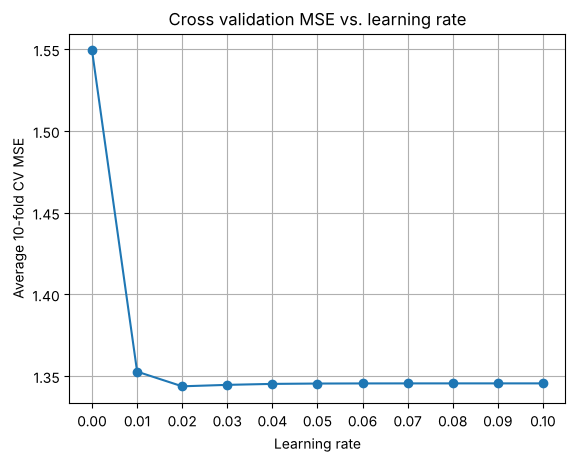

In [5]:
plt.plot(learning_rates, cv_mse, marker='o')
plt.xlabel('Learning rate')
plt.ylabel('Average 10-fold CV MSE')
plt.title('Cross validation MSE vs. learning rate')
plt.xticks(learning_rates)
plt.grid(True)
plt.savefig('cv_mse_vs_learning_rate.png', dpi=150, bbox_inches='tight')
plt.show()

## Result 2: best learning rate

In [6]:
best_i = int(np.argmin(cv_mse))
best_lr = learning_rates[best_i]
print(f'Best learning rate: {best_lr:.2f}')
print(f'Its CV MSE: {cv_mse[best_i]:.4f}')

Best learning rate: 0.02
Its CV MSE: 1.3438


## Result 3: test MSE with the best learning rate
The model is retrained on the full training set before testing.

In [7]:
w_best = train(X_train, y_train, best_lr)
test_mse = mse(y_test, predict(X_test, w_best))
print('Weights (bias, w1, w2):', np.round(w_best, 4))
print(f'Test MSE: {test_mse:.4f}')

Weights (bias, w1, w2): [-0.7667  0.4036  1.4322]
Test MSE: 1.4459
